In [ ]:
# Célula 1 - conexão API
from pathlib import Path

import kagglehub
from dotenv import load_dotenv

# Funciona com o kernel iniciado na raiz do projeto ou dentro de notebooks/
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "requirements.txt").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

env_path = PROJECT_ROOT / ".env"
if not env_path.exists():
    raise FileNotFoundError("Crie o arquivo .env na raiz do projeto com KAGGLE_API_TOKEN.")
load_dotenv(env_path, override=True)

usuario = kagglehub.whoami(verbose=False)["username"]
print(f"Conectado ao Kaggle como: {usuario}")

Conectado ao Kaggle como: peresrodrigo


In [ ]:
# Célula 2 - conexão ao DataSet
from pathlib import Path
from zipfile import ZipFile

import kagglehub
import pandas as pd

DATASET_HANDLE = "yeanzc/telco-customer-churn-ibm-dataset"
DATASET_FILE = "Telco_customer_churn.xlsx"

downloaded_file = Path(
    kagglehub.dataset_download(DATASET_HANDLE, path=DATASET_FILE)
)

# kagglehub 1.0.2 pode manter o ZIP externo no Windows.
with ZipFile(downloaded_file) as archive:
    if DATASET_FILE in archive.namelist():
        with archive.open(DATASET_FILE) as excel_file:
            df = pd.read_excel(excel_file, engine="openpyxl")
    else:
        df = pd.read_excel(downloaded_file, engine="openpyxl")

print(f"Dataset carregado: {df.shape[0]} linhas e {df.shape[1]} colunas")
display(df.head())

Dataset carregado: 7043 linhas e 33 colunas


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [ ]:
# Célula 3 — configuração da EDA e conferência dos nomes de colunas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

ALVO = "Churn Value"   # 1 = cancelou, 0 = ficou

# Colunas que entregam a resposta ao modelo: ficam fora das features
VAZAMENTO = ["Churn Label", "Churn Score", "CLTV", "Churn Reason"]

# Identificação e geografia: não entram como features no baseline
IDENT_GEO = ["CustomerID", "Count", "Country", "State", "City",
             "Zip Code", "Lat Long", "Latitude", "Longitude"]

NUMERICAS = ["Tenure Months", "Monthly Charges", "Total Charges"]

CATEGORICAS = ["Gender", "Senior Citizen", "Partner", "Dependents",
               "Phone Service", "Multiple Lines", "Internet Service",
               "Online Security", "Online Backup", "Device Protection",
               "Tech Support", "Streaming TV", "Streaming Movies",
               "Contract", "Paperless Billing", "Payment Method"]

esperadas = [ALVO] + VAZAMENTO + IDENT_GEO + NUMERICAS + CATEGORICAS
faltando = [c for c in esperadas if c not in df.columns]
extras = [c for c in df.columns if c not in esperadas]
print("Colunas esperadas que não existem no arquivo:", faltando or "nenhuma")
print("Colunas do arquivo fora do mapeamento:", extras or "nenhuma")
assert not faltando, "PARE: nomes de colunas diferentes do esperado. Cole esta saída no chat."

Colunas esperadas que não existem no arquivo: nenhuma
Colunas do arquivo fora do mapeamento: nenhuma


In [ ]:
# Célula 4 — estrutura e qualidade: tipos, nulos, duplicatas, colunas constantes
print("Formato:", df.shape)

resumo = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "nulos": df.isna().sum(),
    "nulos_%": (df.isna().mean() * 100).round(2),
    "valores_unicos": df.nunique(dropna=False),
})
print(resumo.to_string())

print("\nLinhas duplicadas:", df.duplicated().sum())
print("CustomerID duplicados:", df["CustomerID"].duplicated().sum())
print("Colunas constantes:", [c for c in df.columns if df[c].nunique(dropna=False) == 1])

Formato: (7043, 33)
                      tipo  nulos  nulos_%  valores_unicos
CustomerID             str      0     0.00            7043
Count                int64      0     0.00               1
Country                str      0     0.00               1
State                  str      0     0.00               1
City                   str      0     0.00            1129
Zip Code             int64      0     0.00            1652
Lat Long               str      0     0.00            1652
Latitude           float64      0     0.00            1652
Longitude          float64      0     0.00            1651
Gender                 str      0     0.00               2
Senior Citizen         str      0     0.00               2
Partner                str      0     0.00               2
Dependents             str      0     0.00               2
Tenure Months        int64      0     0.00              73
Phone Service          str      0     0.00               2
Multiple Lines         str      0   

In [ ]:
# Célula 5 — Total Charges: tipo, valores inválidos e coerência com Tenure × Monthly
# Na base clássica, clientes com 0 meses de casa têm Total Charges em branco.
print("Tipo original:", df["Total Charges"].dtype)

tc = pd.to_numeric(df["Total Charges"], errors="coerce")
print("Valores vazios ou não numéricos:", tc.isna().sum())
print(df.loc[tc.isna(), ["CustomerID", "Tenure Months", "Monthly Charges", "Total Charges", ALVO]])

# Conversão apenas na memória; o arquivo bruto não é alterado e nada é imputado aqui
df["Total Charges"] = tc

# Total Charges deveria ficar próximo de Tenure × Monthly Charges
estimado = df["Tenure Months"] * df["Monthly Charges"]
desvio = ((df["Total Charges"] - estimado) / estimado).abs().replace(np.inf, np.nan)
print(f"\nDesvio mediano entre Total Charges e Tenure × Monthly: {desvio.median():.1%}")

Tipo original: object
Valores vazios ou não numéricos: 11
      CustomerID  Tenure Months  Monthly Charges Total Charges  Churn Value
2234  4472-LVYGI              0            52.55                          0
2438  3115-CZMZD              0            20.25                          0
2568  5709-LVOEQ              0            80.85                          0
2667  4367-NUYAO              0            25.75                          0
2856  1371-DWPAZ              0            56.05                          0
4331  7644-OMVMY              0            19.85                          0
4687  3213-VVOLG              0            25.35                          0
5104  2520-SGTTA              0            20.00                          0
5719  2923-ARZLG              0            19.70                          0
6772  4075-WKNIU              0            73.35                          0
6840  2775-SEFEE              0            61.90                          0

Desvio mediano entre Total Ch

In [16]:
# Célula 6 — volume e papel de cada variável
df_eda = df.copy()
df_eda["Total Charges"] = pd.to_numeric(df_eda["Total Charges"], errors="coerce")

def papel_coluna(coluna):
    if coluna == ALVO:
        return "alvo"
    if coluna in VAZAMENTO:
        return "vazamento de alvo"
    if coluna in IDENT_GEO:
        return "identificação/geografia"
    if coluna in NUMERICAS:
        return "feature numérica"
    if coluna in CATEGORICAS:
        return "feature categórica"
    return "revisar"

perfil = pd.DataFrame({
    "tipo": df_eda.dtypes.astype(str),
    "papel": [papel_coluna(c) for c in df_eda.columns],
    "n_unicos": df_eda.nunique(dropna=False),
    "n_ausentes": df_eda.isna().sum(),
    "ausentes_%": (df_eda.isna().mean() * 100).round(2),
}).sort_values(["papel", "n_unicos"])

resumo_volume = pd.Series({
    "linhas": len(df_eda),
    "colunas": df_eda.shape[1],
    "memória (MB)": round(df_eda.memory_usage(deep=True).sum() / 1024**2, 2),
    "features candidatas ao baseline": len(NUMERICAS) + len(CATEGORICAS),
    "taxa de churn (%)": round(df_eda[ALVO].mean() * 100, 2),
    "classe majoritária (%)": round(df_eda[ALVO].value_counts(normalize=True).max() * 100, 2),
}, name="valor")
display(resumo_volume.to_frame())
display(perfil)

,valor
linhas,7043.00
colunas,33.00
memória (MB),9.14
features candidatas ao baseline,19.00
taxa de churn (%),26.54
classe majoritária (%),73.46


,tipo,papel,n_unicos,n_ausentes,ausentes_%
Churn Value,int64,alvo,2,0,0.00
Gender,str,feature categórica,2,0,0.00
Senior Citizen,str,feature categórica,2,0,0.00
Partner,str,feature categórica,2,0,0.00
Dependents,str,feature categórica,2,0,0.00
Phone Service,str,feature categórica,2,0,0.00
Paperless Billing,str,feature categórica,2,0,0.00
Multiple Lines,str,feature categórica,3,0,0.00
Internet Service,str,feature categórica,3,0,0.00
Online Security,str,feature categórica,3,0,0.00


,verificação,resultado
0,linhas duplicadas,0
1,CustomerID duplicado,0
2,Total Charges ausente,11
3,colunas constantes,"Count, Country, State"


,outliers_IQR
Tenure Months,0
Monthly Charges,0
Total Charges,0


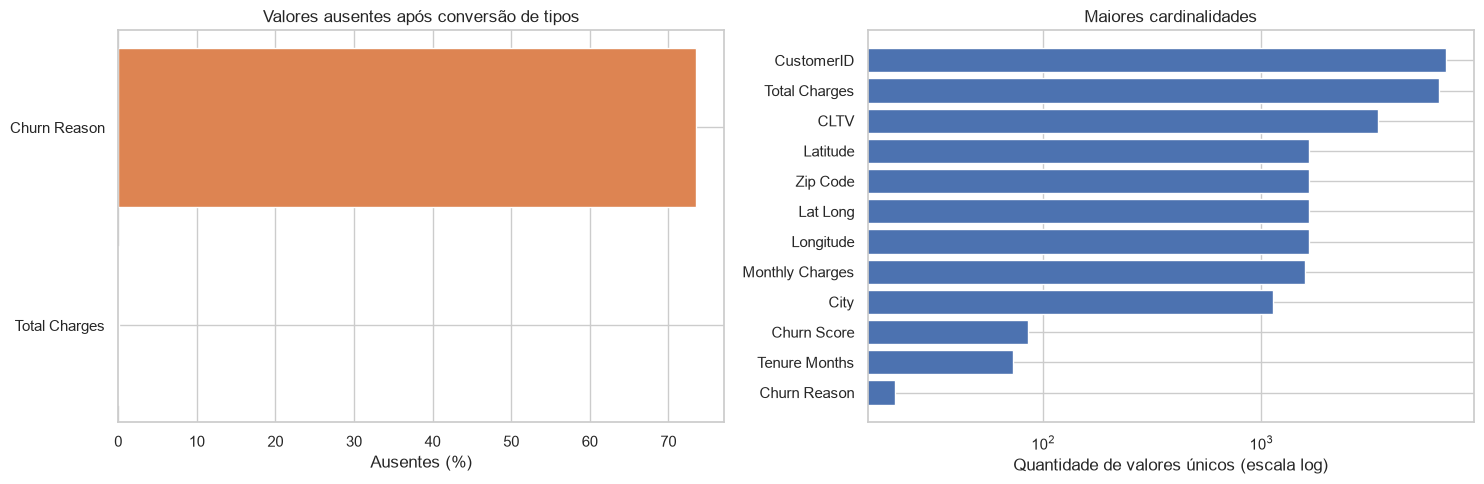

In [17]:
# Célula 7 — qualidade: ausências, duplicidades, constantes, cardinalidade e outliers
def contar_outliers_iqr(serie):
    serie = serie.dropna()
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    limite_inferior, limite_superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return int(((serie < limite_inferior) | (serie > limite_superior)).sum())

alertas_qualidade = pd.DataFrame({
    "verificação": ["linhas duplicadas", "CustomerID duplicado", "Total Charges ausente", "colunas constantes"],
    "resultado": [
        int(df_eda.duplicated().sum()),
        int(df_eda["CustomerID"].duplicated().sum()),
        int(df_eda["Total Charges"].isna().sum()),
        ", ".join(df_eda.columns[df_eda.nunique(dropna=False) == 1]),
    ],
})
outliers = pd.DataFrame({
    "outliers_IQR": {col: contar_outliers_iqr(df_eda[col]) for col in NUMERICAS}
})
display(alertas_qualidade)
display(outliers)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ausentes = (df_eda.isna().mean() * 100).sort_values(ascending=True)
ausentes = ausentes[ausentes > 0]
if ausentes.empty:
    axes[0].text(0.5, 0.5, "Nenhum valor ausente", ha="center", va="center")
    axes[0].set_axis_off()
else:
    axes[0].barh(ausentes.index, ausentes.values, color="#dd8452")
    axes[0].set_xlabel("Ausentes (%)")
    axes[0].set_title("Valores ausentes após conversão de tipos")

cardinalidade = df_eda.nunique(dropna=False).sort_values(ascending=False).head(12).sort_values()
axes[1].barh(cardinalidade.index, cardinalidade.values, color="#4c72b0")
axes[1].set_xscale("log")
axes[1].set_xlabel("Quantidade de valores únicos (escala log)")
axes[1].set_title("Maiores cardinalidades")
plt.tight_layout()
plt.show()

,quantidade,percentual
Churn Value,,
0,5174,73.46
1,1869,26.54


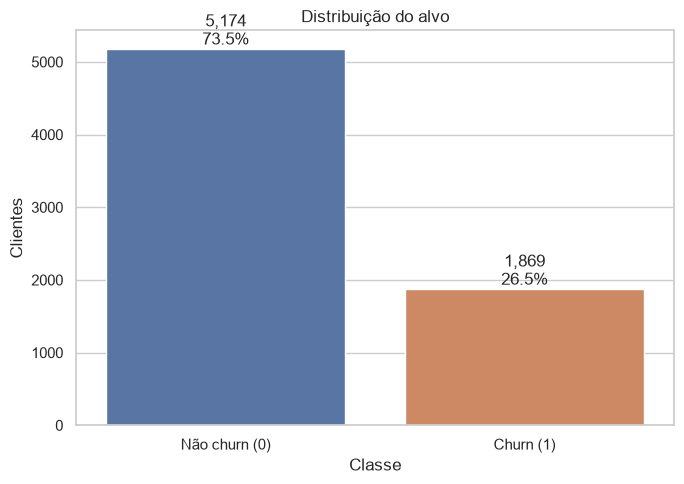

Acurácia ingênua ao prever sempre a classe majoritária: 73.46%


In [18]:
# Célula 8 — distribuição da variável alvo e desbalanceamento
contagem_alvo = df_eda[ALVO].value_counts().sort_index()
percentual_alvo = df_eda[ALVO].value_counts(normalize=True).sort_index() * 100
display(pd.DataFrame({"quantidade": contagem_alvo, "percentual": percentual_alvo.round(2)}))

fig, ax = plt.subplots(figsize=(7, 5))
sns.countplot(data=df_eda, x=ALVO, hue=ALVO, palette=["#4c72b0", "#dd8452"], legend=False, ax=ax)
ax.set_xticks([0, 1], ["Não churn (0)", "Churn (1)"])
ax.set_xlabel("Classe")
ax.set_ylabel("Clientes")
ax.set_title("Distribuição do alvo")
for indice, barra in enumerate(ax.patches):
    ax.annotate(f"{int(barra.get_height()):,}\n{percentual_alvo.iloc[indice]:.1f}%",
                (barra.get_x() + barra.get_width() / 2, barra.get_height()),
                ha="center", va="bottom")
plt.tight_layout()
plt.show()
print(f"Acurácia ingênua ao prever sempre a classe majoritária: {contagem_alvo.max() / len(df_eda):.2%}")

,count,mean,std,min,1%,25%,50%,75%,99%,max
Tenure Months,7043.0,32.371149,24.559481,0.00,1.0,9.00,29.000,55.0000,72.000,72.00
Monthly Charges,7043.0,64.761692,30.090047,18.25,19.2,35.50,70.350,89.8500,114.729,118.75
Total Charges,7032.0,2283.300441,2266.771362,18.80,19.9,401.45,1397.475,3794.7375,8039.883,8684.80


Tenure Months               Monthly Charges                \
                     mean median    std            mean median    std   
Churn Value                                                             
0                   37.57   38.0  24.11           61.27  64.43  31.09   
1                   17.98   10.0  19.53           74.44  79.65  24.67   

            Total Charges                    
                     mean   median      std  
Churn Value                                  
0                 2555.34  1683.60  2329.46  
1                 1531.80   703.55  1890.82

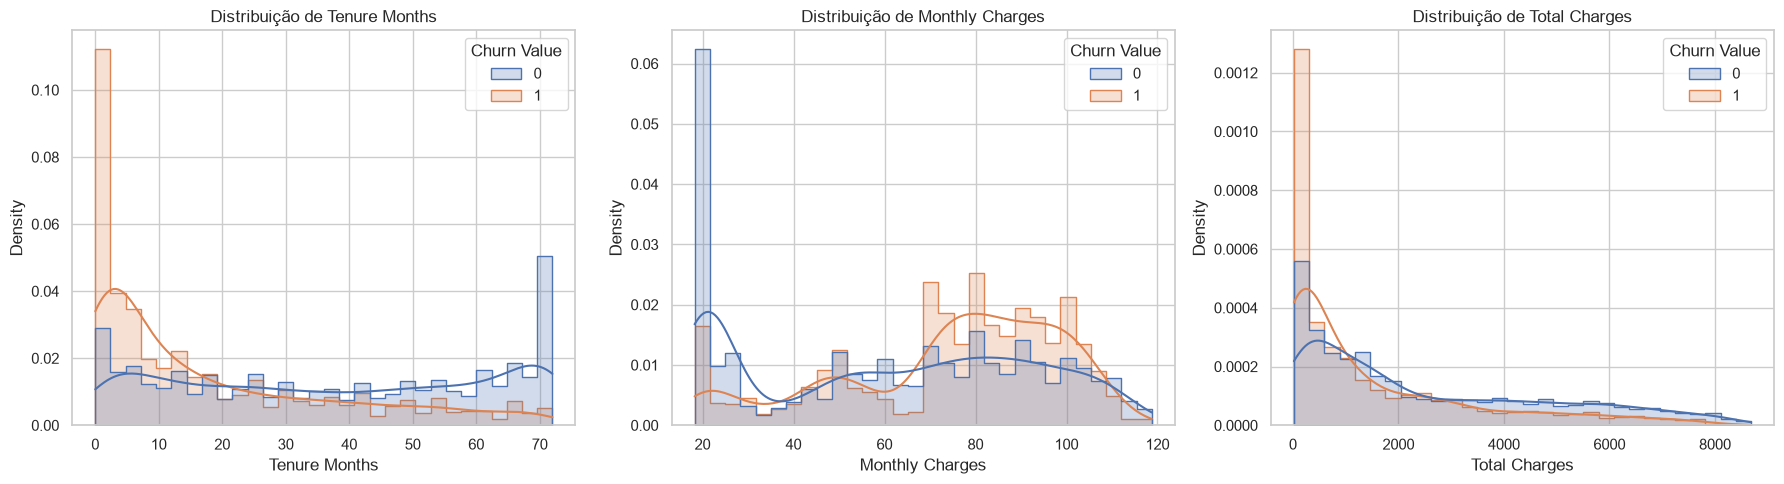

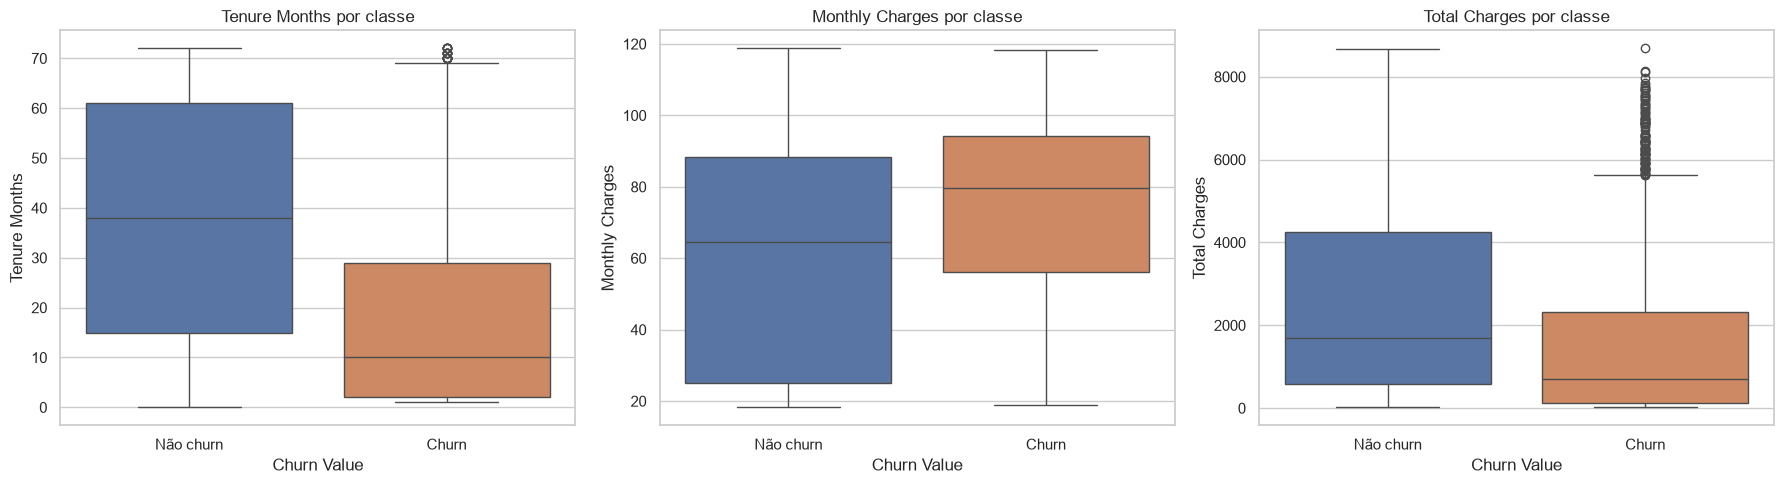

In [19]:
# Célula 9 — distribuição das features numéricas e comparação por churn
display(df_eda[NUMERICAS].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T)
display(df_eda.groupby(ALVO)[NUMERICAS].agg(["mean", "median", "std"]).round(2))

fig, axes = plt.subplots(1, len(NUMERICAS), figsize=(18, 5))
for ax, coluna in zip(axes, NUMERICAS):
    sns.histplot(data=df_eda, x=coluna, hue=ALVO, bins=30, kde=True,
                 element="step", stat="density", common_norm=False, ax=ax)
    ax.set_title(f"Distribuição de {coluna}")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, len(NUMERICAS), figsize=(18, 5))
for ax, coluna in zip(axes, NUMERICAS):
    sns.boxplot(data=df_eda, x=ALVO, y=coluna, hue=ALVO, legend=False, ax=ax)
    ax.set_xticks([0, 1], ["Não churn", "Churn"])
    ax.set_title(f"{coluna} por classe")
plt.tight_layout()
plt.show()

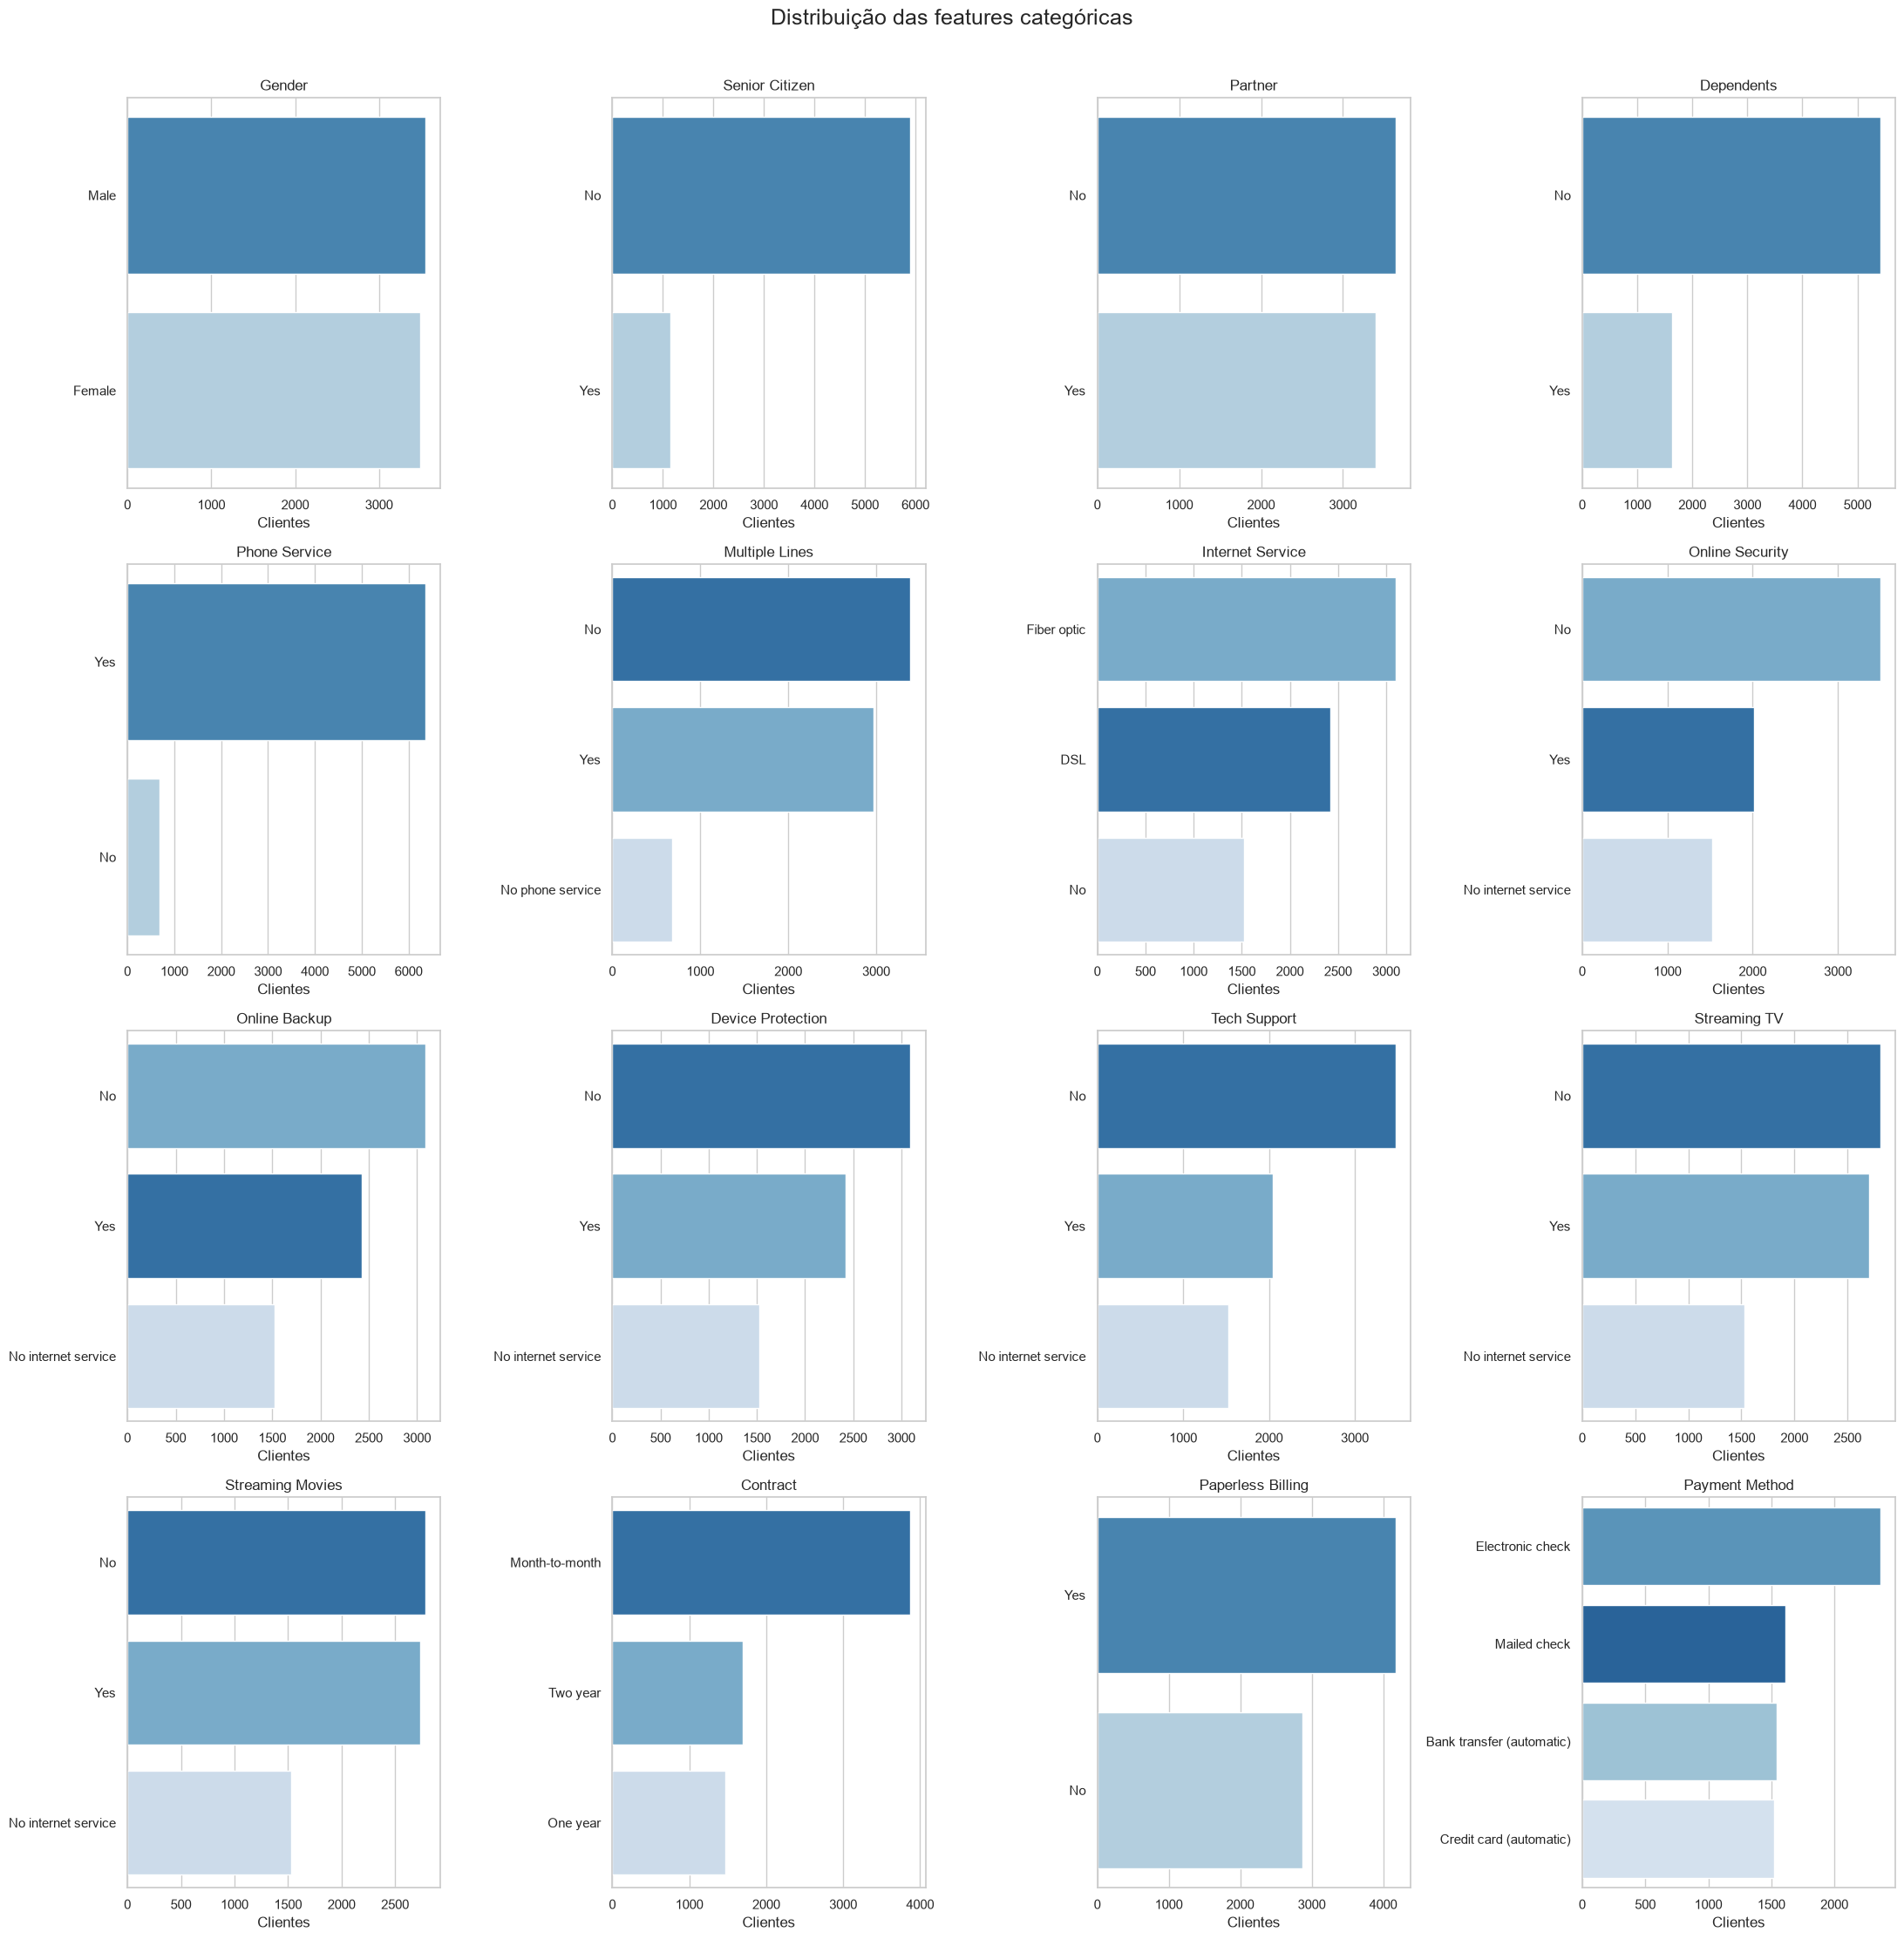

In [20]:
# Célula 10 — distribuição das features categóricas
fig, axes = plt.subplots(4, 4, figsize=(22, 22))
for ax, coluna in zip(axes.flat, CATEGORICAS):
    ordem = df_eda[coluna].value_counts().index
    sns.countplot(data=df_eda, y=coluna, hue=coluna, order=ordem, palette="Blues_r", legend=False, ax=ax)
    ax.set_title(coluna)
    ax.set_xlabel("Clientes")
    ax.set_ylabel("")
fig.suptitle("Distribuição das features categóricas", fontsize=18, y=1.01)
plt.tight_layout()
plt.show()

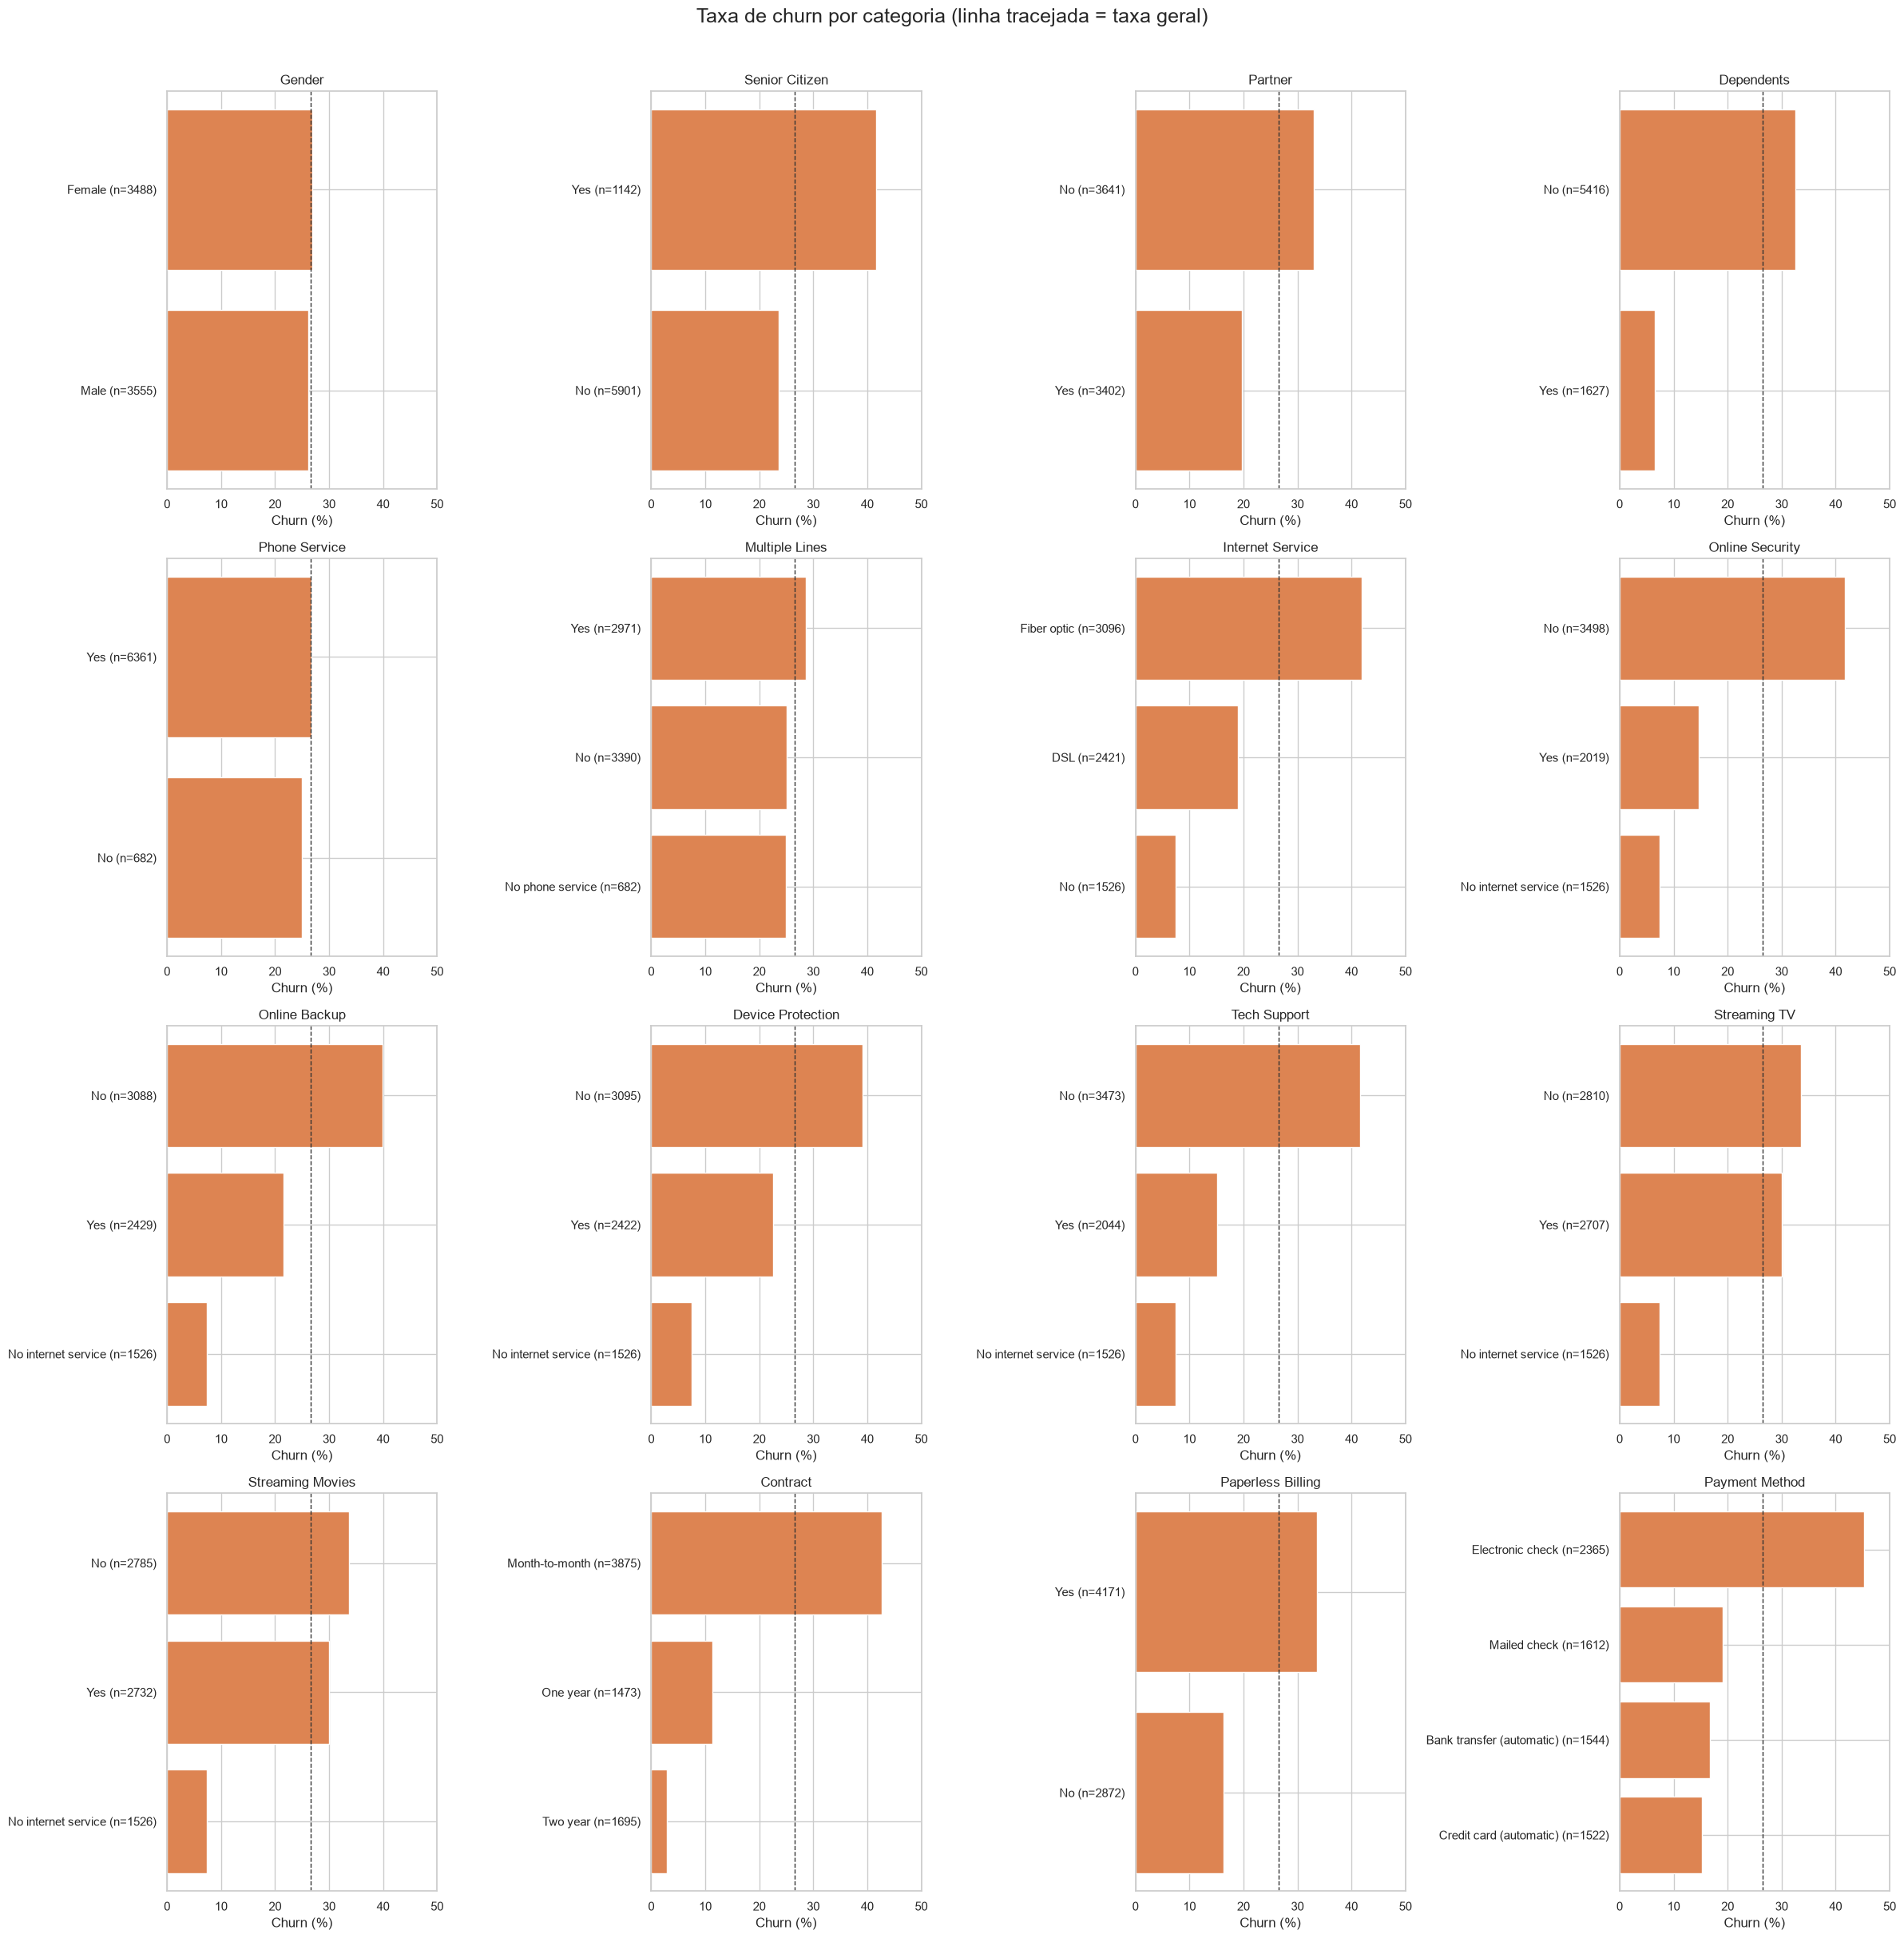

In [21]:
# Célula 11 — taxa de churn por categoria, com tamanho de cada grupo
taxa_geral = df_eda[ALVO].mean()
fig, axes = plt.subplots(4, 4, figsize=(24, 24))
for ax, coluna in zip(axes.flat, CATEGORICAS):
    resumo = (df_eda.groupby(coluna, observed=True)[ALVO]
              .agg(taxa="mean", n="size")
              .sort_values("taxa"))
    rotulos = [f"{indice} (n={n})" for indice, n in zip(resumo.index.astype(str), resumo["n"])]
    ax.barh(rotulos, resumo["taxa"] * 100, color="#dd8452")
    ax.axvline(taxa_geral * 100, color="#333333", linestyle="--", linewidth=1)
    ax.set_title(coluna)
    ax.set_xlabel("Churn (%)")
    ax.set_xlim(0, max(50, resumo["taxa"].max() * 110))
fig.suptitle("Taxa de churn por categoria (linha tracejada = taxa geral)", fontsize=18, y=1.01)
plt.tight_layout()
plt.show()

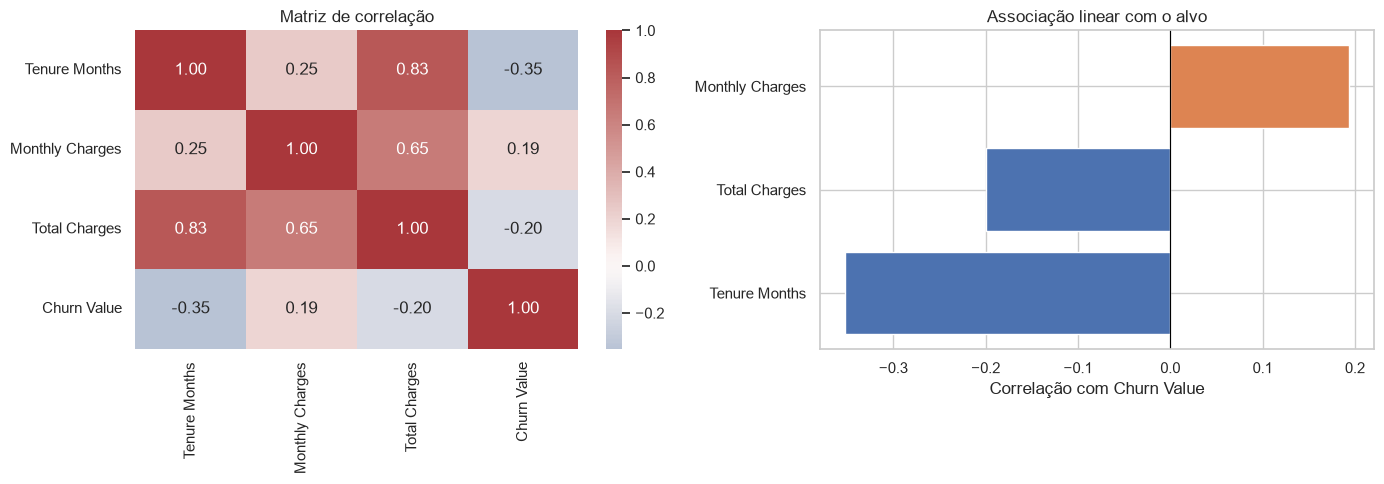

In [22]:
# Célula 12 — correlação entre variáveis numéricas e o alvo
correlacoes = df_eda[NUMERICAS + [ALVO]].corr(numeric_only=True)
correlacao_alvo = correlacoes[ALVO].drop(ALVO).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(correlacoes, annot=True, fmt=".2f", cmap="vlag", center=0, ax=axes[0])
axes[0].set_title("Matriz de correlação")
cores = ["#4c72b0" if valor < 0 else "#dd8452" for valor in correlacao_alvo]
axes[1].barh(correlacao_alvo.index, correlacao_alvo.values, color=cores)
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_xlabel("Correlação com Churn Value")
axes[1].set_title("Associação linear com o alvo")
plt.tight_layout()
plt.show()

In [23]:
# Célula 13 — conclusões da EDA e contrato de dados para o baseline
def taxa_categoria(coluna, categoria):
    return df_eda.loc[df_eda[coluna] == categoria, ALVO].mean()

medianas_tenure = df_eda.groupby(ALVO)["Tenure Months"].median()
insights = [
    f"A base tem {len(df_eda):,} clientes e {df_eda.shape[1]} colunas; churn geral de {taxa_geral:.1%}.",
    f"Há {df_eda['Total Charges'].isna().sum()} ausências em Total Charges; devem ser imputadas dentro do pipeline para evitar vazamento.",
    f"Clientes com contrato mensal apresentam churn de {taxa_categoria('Contract', 'Month-to-month'):.1%}.",
    f"Fibra óptica apresenta churn de {taxa_categoria('Internet Service', 'Fiber optic'):.1%}.",
    f"Pagamento por cheque eletrônico apresenta churn de {taxa_categoria('Payment Method', 'Electronic check'):.1%}.",
    f"A mediana de tenure é {medianas_tenure.loc[0]:.0f} meses sem churn e {medianas_tenure.loc[1]:.0f} meses com churn.",
    "Count, Country e State são constantes; identificadores/geografia e variáveis de vazamento não entrarão no baseline.",
]
print("PRINCIPAIS ACHADOS")
for insight in insights:
    print("-", insight)

plano_baseline = pd.Series({
    "alvo": ALVO,
    "numéricas": ", ".join(NUMERICAS),
    "categóricas": f"{len(CATEGORICAS)} colunas com OneHotEncoder(handle_unknown='ignore')",
    "tratamento numérico": "imputação pela mediana + StandardScaler, ajustados somente no treino",
    "exclusões": "IDs/geografia, constantes e Churn Label/Score/Reason/CLTV",
    "validação": "train/test estratificado com random_state fixo; idealmente CV estratificada no treino",
    "métricas": "ROC-AUC e PR-AUC; complementar com recall, precision, F1 e matriz de confusão",
    "referência": f"comparar com o classificador majoritário ({contagem_alvo.max() / len(df_eda):.2%} de acurácia)",
}, name="decisão")
display(plano_baseline.to_frame())

FEATURES_BASELINE = NUMERICAS + CATEGORICAS
X_eda = df_eda[FEATURES_BASELINE].copy()
y_eda = df_eda[ALVO].astype(int).copy()
print(f"\nMatriz pronta para o próximo passo: X={X_eda.shape}, y={y_eda.shape}")

PRINCIPAIS ACHADOS
- A base tem 7,043 clientes e 33 colunas; churn geral de 26.5%.
- Há 11 ausências em Total Charges; devem ser imputadas dentro do pipeline para evitar vazamento.
- Clientes com contrato mensal apresentam churn de 42.7%.
- Fibra óptica apresenta churn de 41.9%.
- Pagamento por cheque eletrônico apresenta churn de 45.3%.
- A mediana de tenure é 38 meses sem churn e 10 meses com churn.
- Count, Country e State são constantes; identificadores/geografia e variáveis de vazamento não entrarão no baseline.


,decisão
alvo,Churn Value
numéricas,"Tenure Months, Monthly Charges, Total Charges"
categóricas,16 colunas com OneHotEncoder(handle_unknown='i...
tratamento numérico,"imputação pela mediana + StandardScaler, ajust..."
exclusões,"IDs/geografia, constantes e Churn Label/Score/..."
validação,train/test estratificado com random_state fixo...
métricas,"ROC-AUC e PR-AUC; complementar com recall, pre..."
referência,comparar com o classificador majoritário (73.4...



Matriz pronta para o próximo passo: X=(7043, 19), y=(7043,)
